# CNN multi classification model

Building simple bench marking exploration focused CNN network for multiclass classification model for brain desease classification.

Building the augmentation file from the raw dataset, with ultra skwed distribution with the actual dataset, we need to set strict weights and penalization for the minority class during training due to huge dataset imbalance


{'cerebral calcinosi': 0, 'normal': 1, 'epilepsy': 2, 'stroke': 3, 'multiple sclerosis': 4, 'alzheimer': 5, 'meningioma': 6}
label
4    1003
5     717
1      99
6      57
0      56
3      44
2      30
Name: count, dtype: int64


<Axes: title={'center': 'class distribution'}, xlabel='label'>

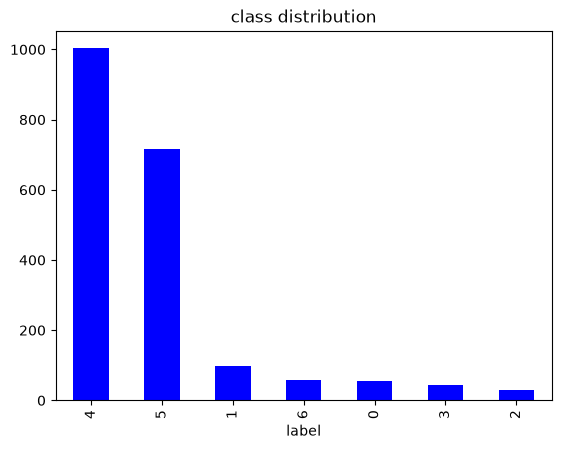

In [12]:
# Dataset alignment
import pandas as pd
from pathlib import Path
import numpy as np 

target_dir = Path('/home/madhav/workstation/Lab/experiment/data/BrainMRI')

dataset = []
for item in target_dir.iterdir():
    label = (item.name).lower()
    for image in item.iterdir():
        path = image.resolve() # absolute path
        dataset.append({
            'image_path': path,
            'label' : label
        })
df = pd.DataFrame(dataset)

disease = list(df['label'].unique())
mapping = {} # GLOBAL ENCODING OBJECT
i = 0
for ill in disease:
    mapping[ill] = i
    i += 1

# Loading map to the dataset
df['label'] = df['label'].map(mapping)

# Simple distribution plot for each class
print(mapping)
distribution = df['label'].value_counts()

print(distribution)

distribution.plot(kind='bar', color='blue', title='class distribution')